# PhoBERT Fine-Tuning: Property Asking-Price Prediction from Listing Text

## 1. Title and Objective

Fine-tune the pretrained Vietnamese language model PhoBERT to predict the asking price from the
listing **text only** (title and description), and compare it with TF-IDF + Ridge, which sees exactly
the same price-redacted information. Any difference therefore reflects how well each model
*understands* the text, not how much information it receives. A built-in ablation compares a naive
fine-tuning run with the full recipe of fine-tuning techniques.

Source: [vduydong/vietnam-real-estates](https://huggingface.co/datasets/vduydong/vietnam-real-estates),
revision `a9a66ffa985edcf76b4be59ae2c6f5b1db889c38`. The dataset credits TiniX AI and specifies
CC BY-NC 4.0. The outcome is the recorded asking price in VND, not a verified transaction price.
Pretrained model: [`vinai/phobert-base-v2`](https://huggingface.co/vinai/phobert-base-v2)
(Nguyen & Nguyen, 2020).

## 2. Experimental Setup

This notebook needs a GPU and is intended for Google Colab (*Runtime → Change runtime type → T4 GPU*).
Locally, run `python -m experiments.prepare` and `python -m experiments.text_vi`, then
`python scripts/pack_colab.py`, and unzip the bundle into `MyDrive/261-dl/` (see `EXPERIMENTS.md`).
The first cell mounts Drive and moves into the bundle, so every result is written to Drive and
survives the end of the Colab session.

The pretrained weights (~540 MB) are downloaded from the Hugging Face Hub on first use. Seeds are
fixed as in notebook 08. On a GPU, some PyTorch kernels (e.g. the embedding backward pass) use
atomic additions, so repeated runs can differ in the last digits; the protocol (data, split,
selection rule) is identical.

In [1]:
from pathlib import Path
import os
import sys

try:  # Google Colab: work inside the unzipped bundle on Drive so results persist.
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/261-dl/models")
except ImportError:
    pass

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "experiments").is_dir() and (path / "requirements.txt").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from transformers import AutoModel, AutoTokenizer
from experiments.data import load_data, SEED
from experiments.evaluation import (
    select_candidate, inverse_log, record_result, diagnostics, comparison_table, environment,
)
from experiments.deep import set_seed, get_device
from experiments.phobert import (
    MODEL_NAME, MAX_LENGTH, load_text, tokenize, TextDataset, make_loader,
    PhoBERTRegressor, layerwise_groups, predict_log, fit,
)

set_seed(SEED)
DEVICE = get_device()
if DEVICE.type != "cuda":
    print("WARNING: no GPU. Fine-tuning PhoBERT on CPU takes many hours; "
          "use Colab with Runtime -> Change runtime type -> GPU.")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.dpi": 300})
parts, manifest = load_data()
train, validation, test = (parts[name] for name in ["train", "validation", "test"])
texts = load_text(parts)
y_train = train.price.to_numpy()
y_validation = validation.price.to_numpy()
log_y_train = np.log1p(y_train)
log_y_validation = np.log1p(y_validation)
display(pd.Series({"Seed": SEED, "Device": str(DEVICE),
                   "GPU": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "none",
                   "Pretrained model": MODEL_NAME, "Max tokens": MAX_LENGTH,
                   "Split SHA-256": manifest["split_sha256"]}, name="Setting").to_frame())
display(pd.Series(environment()["packages"], name="Installed version").to_frame())


Mounted at /content/drive


,Setting
Seed,42
Device,cuda
GPU,Tesla T4
Pretrained model,vinai/phobert-base-v2
Max tokens,256
Split SHA-256,15340296092993fac87fe7f2cd02c9635da706a0510a79...


,Installed version
numpy,2.4.6
pandas,2.2.3
pyarrow,23.0.1
scikit-learn,1.6.1
lightgbm,4.6.0
catboost,None
matplotlib,3.10.0
torch,2.14.1+cu130
transformers,5.22.1


## 3. Dataset Overview

The text input is `text_vi_seg` from `data/processed/text_vi.parquet`, joined to the frozen cohort by
`row_id`. It applies **the same redaction rule** as the TF-IDF notebook (clauses with monetary cues
are dropped, every digit-bearing token is removed) but keeps Vietnamese diacritics, which the cohort's
accent-stripped `text` column had removed. Stripping the accents from this text reproduces the
TF-IDF input exactly for 59,518 of 59,519 listings; the one exception uses styled
Unicode letters (see `reports/experiments/text_vi_manifest.json`). Fewer than 0.5% of listings have
no text left after redaction; they are encoded as an empty sequence.

In [2]:
display(pd.DataFrame([
    {"Split": name, "Listings": len(frame),
     "Empty text after redaction": float(np.mean([t == "" for t in texts[name]])),
     "Median words": float(np.median([len(t.split()) for t in texts[name]]))}
    for name, frame in parts.items()
]).set_index("Split"))
print("Example (segmented, price-redacted):", texts["train"][0][:300])


,Listings,Empty text after redaction,Median words
Split,,,
train,41663,0.004248,65.0
validation,8928,0.005264,67.0
test,8928,0.004928,65.0


Example (segmented, price-redacted): Căn_hộ một bước ra biển SunGroup chỉ cam_kết thu trên / tháng Ngồi du_thuyền ngắm pháo Cát_Bà với lượng khách du_lịch khủng với Sự hoang_sơ thiên_nhiên nhưng đang thiếu phòng và nơi vui_chơi Nổi_bật với Bãi biển lặng sóng và đẹp nhất miền Bắc du_khách đến Cát_Bà đợt / - / lên tới hơn người Tới đây k


## 4. Data Preprocessing

The first cell repeats the protocol's leakage checks and additionally asserts that no digit survives the redaction, so the model cannot read a price, an area or a room count from the text.

**Word segmentation.** Vietnamese is written in syllables separated by spaces; a word such as *bất động sản* spans three syllables. PhoBERT was pretrained on text segmented by RDRSegmenter (VnCoreNLP), which joins the syllables of a word with underscores (`bất_động_sản`). Fine-tuning inputs must be prepared the same way as pretraining inputs; otherwise the model faces a different input distribution than the one its weights were learned on.

**Tokenization.** PhoBERT's tokenizer splits words into byte-pair-encoding (BPE) units from a 64,000-entry vocabulary; a trailing `@@` marks a piece that continues into the next one. Texts are tokenized once, with `<s>` and `</s>` added, and truncated to `max_length = 256`: PhoBERT has 258 position embeddings, two of which are reserved. The table and histogram below show how many listings are affected by truncation.

In [3]:
assert train.published_at.max() < validation.published_at.min()
assert validation.published_at.max() < test.published_at.min()
assert set(train.group_id).isdisjoint(validation.group_id)
assert set(train.group_id).isdisjoint(test.group_id)
assert set(validation.group_id).isdisjoint(test.group_id)
assert not any(ch.isdigit() for t in texts["train"][:2000] for ch in t), "digits must be redacted"


config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

,Training text
Median tokens,78.0000
95th percentile,179.0000
99th percentile,274.0000
Share truncated at 256,0.0131
Share of tokens,0.0002


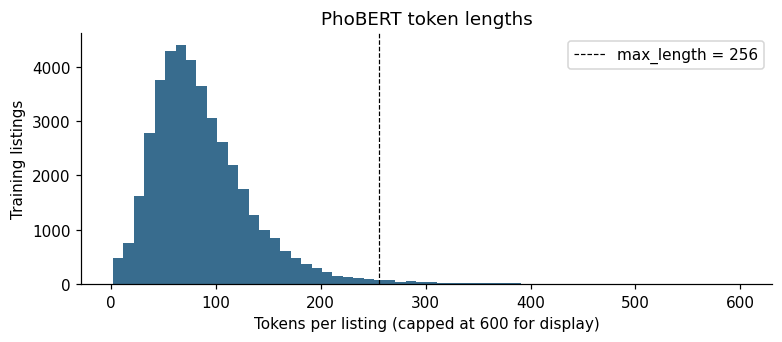

['<s>', 'Căn_hộ', 'một', 'bước', 'ra', 'biển', 'Sun@@', 'Group', 'chỉ', 'cam_kết', 'thu', 'trên', '/', 'tháng', 'Ngồi', 'du_thuyền', 'ngắm', 'pháo', 'Cát_Bà', 'với', 'lượng', 'khách', 'du_lịch', 'khủng', 'với', 'Sự', 'hoang_sơ', 'thiên_nhiên', 'nhưng', 'đang', 'thiếu', 'phòng', 'và', 'nơi', 'vui_chơi', 'Nổi_bật', 'với', 'Bãi', 'biển', 'lặng']


In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
untruncated = tokenizer(texts["train"], truncation=False)["input_ids"]
lengths = np.array([len(ids) for ids in untruncated])
ids = {name: tokenize(tokenizer, texts[name]) for name in ["train", "validation", "test"]}
display(pd.Series({
    "Median tokens": np.median(lengths), "95th percentile": np.percentile(lengths, 95),
    "99th percentile": np.percentile(lengths, 99),
    f"Share truncated at {MAX_LENGTH}": float((lengths > MAX_LENGTH).mean()),
    "Share of <unk> tokens": float(np.mean(np.concatenate(untruncated) == tokenizer.unk_token_id)),
}, name="Training text").to_frame().style.format("{:,.4f}"))
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.hist(np.minimum(lengths, 600), bins=60, color="#386c8e")
ax.axvline(MAX_LENGTH, color="black", linestyle="--", linewidth=.8, label=f"max_length = {MAX_LENGTH}")
ax.set(xlabel="Tokens per listing (capped at 600 for display)", ylabel="Training listings",
       title="PhoBERT token lengths")
ax.legend()
plt.show()
print(tokenizer.convert_ids_to_tokens(ids["train"][0][:40]))


## 5. Feature Engineering

The model learns its own text representation; the engineering decisions concern the input form. Measured on 2,000 sampled listings while preparing this notebook:

| Text given to PhoBERT | Tokens per syllable | Share of BPE fragments | Truncated at 256 |
|---|---:|---:|---:|
| Accent-stripped (cohort `text`) | 1.32 | 24.0% | 7.1% |
| Accented | 1.10 | 8.9% | 3.6% |
| **Accented and word-segmented (used here)** | **0.89** | 14.0% | **1.5%** |

Without diacritics many syllables become ambiguous (*ban* = bán / bàn / bạn / bản) and fall outside the pretraining vocabulary, so they are cut into nearly three times as many fragments. The prepared text yields about 0.02% unknown tokens.

**Mean pooling.** The listing vector is the average of the final hidden states of all real tokens, ignoring padding; for regression, price information is spread over the whole text rather than concentrated in one position.

**Dynamic padding.** Each batch is padded only to its longest sequence. With a median of about 80 tokens, this avoids most of the computation that fixed padding to 256 would waste.

## 6. Model Implementation

    tokens → PhoBERT encoder (12 Transformer layers, 768 hidden units, 12 heads)
           → mean pooling over real tokens → Dropout → Linear(768, 256) → GELU → Dropout
           → Linear(256, 1) → log1p(price)

**Self-attention.** Every layer computes, for each token, queries $Q$, keys $K$ and values $V$ and mixes
information from all tokens with weights
$\operatorname{softmax}\left(QK^\top / \sqrt{d_k}\right)V$. A token's representation therefore depends on
its context: *mặt tiền* in "nhà mặt tiền đường lớn" and in "mặt tiền 4m" receives different vectors,
whereas TF-IDF assigns one fixed weight per term. The cost grows with $O(n^2)$ in sequence length,
which is one reason for the 256-token limit.

**Transfer learning.** The encoder was pretrained by masked language modelling: 15% of tokens are hidden
and must be predicted from context, which forces the network to learn vocabulary, syntax and meaning.
Training a 135-million-parameter Transformer from scratch on 41,663 listings would overfit severely;
starting from pretrained weights and adapting them is feasible.

**Head.** A small MLP maps the pooled vector to the log price. Its output bias starts at the mean
training log price, as in notebook 08, so early updates are not spent learning a constant.

The table below lists the parameter groups created by layer-wise learning-rate decay (Section 7).

In [5]:
def build_model():
    encoder = AutoModel.from_pretrained(MODEL_NAME)
    return PhoBERTRegressor(encoder, head_hidden=256, dropout=0.1,
                            target_mean=float(log_y_train.mean())).to(DEVICE)

set_seed(SEED)
probe = build_model()
groups = layerwise_groups(probe, base_lr=3e-5, head_lr=1e-3, decay=0.9, weight_decay=0.01)
print(f"Trainable parameters: {sum(p.numel() for g in groups for p in g['params']):,} "
      f"(pretrained pooler excluded; it has no pretrained weights)")
display(pd.DataFrame([{"Learning rate": g["lr"], "Weight decay": g["weight_decay"],
                       "Head": g["is_head"], "Parameters": sum(p.numel() for p in g["params"])}
                      for g in groups]).groupby(["Learning rate", "Head"]).Parameters.sum()
        .sort_index(ascending=False).to_frame())
del probe, groups
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 134,604,801 (pretrained pooler excluded; it has no pretrained weights)


,,Parameters
Learning rate,Head,
0.001000,True,197121
0.000030,False,7087872
0.000027,False,7087872
0.000024,False,7087872
0.000022,False,7087872
0.000020,False,7087872
0.000018,False,7087872
0.000016,False,7087872
0.000014,False,7087872


## 7. Hyperparameter Configuration

The central risk in fine-tuning is **catastrophic forgetting**: large updates overwrite what the
pretrained weights encode. Each technique below limits that risk in a different way.

| Technique | Mechanism | Reason |
|---|---|---|
| Small learning rate (3e-5) | small steps for the encoder | pretrained weights are already close to useful values |
| **Layer-wise LR decay** | layer $l$ uses $\text{lr}_{\text{top}} \cdot \gamma^{\,11-l}$; embeddings $\gamma^{12}$ | lower layers encode general knowledge (morphology, syntax) and should change least; upper layers are closer to the task (Howard & Ruder, 2018; Sun et al., 2019) |
| **Frozen-encoder head warm-up** (300 steps) | only the new head is trained at first | a randomly initialized head sends large, noisy gradients that would distort pretrained features (Kumar et al., 2022) |
| **Linear warm-up, then linear decay** | the LR rises from zero over 6% of the steps | Adam's second-moment estimates are unreliable in the first steps and can produce very large updates |
| Separate encoder warm-up | the encoder's LR stays at zero until unfreezing, then warms up | otherwise the encoder would meet the full LR the moment it is unfrozen |
| Separate head LR (1e-3) | the head learns faster | it is new and has nothing to forget |
| No weight decay on biases and LayerNorm | only weight matrices are shrunk | pulling scale/shift parameters towards zero damages normalization |

All candidates use AdamW, Huber loss ($\delta = 1$) on $\log(1+\text{price})$ for the reasons given in
notebook 08, batch size 32, at most 4 epochs and gradient clipping at norm 1.

| Candidate | Recipe | Question |
|---|---|---|
| 0 | full recipe, top LR 3e-5, $\gamma = 0.9$ | reference |
| 1 | **naive**: one LR (3e-5) for every parameter, no decay, no freezing | do the techniques help? (ablation) |
| 2 | full recipe, top LR 5e-5, $\gamma = 0.85$ | is a larger top LR with steeper decay better? |

If GPU memory runs out, set `batch_size` to 16 and `accumulation` to 2: gradients are summed over two
batches before each update, so the effective batch size stays 32.

In [6]:
SHARED = {"epochs": 4, "batch_size": 32, "accumulation": 1, "weight_decay": 0.01,
          "warmup_ratio": 0.06, "huber_delta": 1.0}
candidates = [
    {**SHARED, "base_lr": 3e-5, "head_lr": 1e-3, "layer_decay": 0.9, "freeze_steps": 300},
    {**SHARED, "base_lr": 3e-5, "head_lr": 3e-5, "layer_decay": 1.0, "freeze_steps": 0},
    {**SHARED, "base_lr": 5e-5, "head_lr": 1e-3, "layer_decay": 0.85, "freeze_steps": 300},
]
display(pd.DataFrame(candidates))


,epochs,batch_size,accumulation,weight_decay,warmup_ratio,huber_delta,base_lr,head_lr,layer_decay,freeze_steps
0,4,32,1,0.01,0.06,1.0,0.00003,0.00100,0.90,300
1,4,32,1,0.01,0.06,1.0,0.00003,0.00003,1.00,0
2,4,32,1,0.01,0.06,1.0,0.00005,0.00100,0.85,300


## 8. Model Training

- **Mixed precision (fp16).** The forward and backward passes run in half precision on the GPU's
  Tensor Cores, roughly halving memory and multiplying throughput; the loss is computed in fp32.
  Small fp16 gradients can underflow to zero, so `GradScaler` multiplies the loss before
  backpropagation and divides the gradients again before the update, skipping steps that overflow.
- **Gradient clipping** at global norm 1, applied after unscaling.
- **Early stopping.** Validation MAE of log price is evaluated twice per epoch; training stops after
  two evaluations without improvement and the best weights are restored. Each candidate restarts
  from the pretrained weights with the same seed.

Validation data drive early stopping and candidate selection, so the selected validation score is
optimistic; the test partition is used once, afterwards. The selected weights are saved to
`models/phobert_best.pt` on Drive (about 540 MB, ignored by Git) for the explanation analysis.

The left plot compares the validation curves of all candidates (the ablation). The right plot shows
the selected schedule at the evaluation steps; the encoder's rate starts at zero during the head
warm-up when the full recipe is selected.

In [ ]:
pad = tokenizer.pad_token_id
train_data = TextDataset(ids["train"], log_y_train)
validation_loader = make_loader(TextDataset(ids["validation"]), 128, False, pad)
test_loader = make_loader(TextDataset(ids["test"]), 128, False, pad)
histories = []

def fit_candidate(parameters):
    set_seed(SEED)
    model = build_model()
    loader = make_loader(train_data, parameters["batch_size"], True, pad, seed=SEED)
    settings = {k: v for k, v in parameters.items() if k != "batch_size"}
    history, best_step = fit(model, loader, validation_loader, log_y_validation, DEVICE,
                             **settings, log_every=200)
    histories.append(history)
    model.best_step_ = best_step
    return model

def predict_vnd(model, loader):
    return inverse_log(predict_log(model, loader, DEVICE), y_train)

model, selected_parameters, tuning_results = select_candidate(
    candidates, fit_candidate, y_validation, lambda m: predict_vnd(m, validation_loader))
selected_index = candidates.index(selected_parameters)
tuning_results["best_step"] = [int(h.index[h.best].max()) for h in histories]
display(tuning_results)
display(pd.Series(selected_parameters, dtype=object, name="Selected value").to_frame())

checkpoint = ROOT / "models" / "phobert_best.pt"   
checkpoint.parent.mkdir(parents=True, exist_ok=True)
torch.save({"state_dict": model.state_dict(), "parameters": selected_parameters,
            "model_name": MODEL_NAME}, checkpoint)


model.safetensors: reconstructing file:   0%|          |  0.00B /  540MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


step   200/5204 train Huber 0.3985 20s
step   400/5204 train Huber 0.3511 60s
step   600/5204 train Huber 0.3216 125s
  eval step 650: val log-MAE 0.5165 *
step   800/5204 train Huber 0.2332 218s
step  1000/5204 train Huber 0.2201 282s
step  1200/5204 train Huber 0.2127 347s
  eval step 1300: val log-MAE 0.4890 *
step  1400/5204 train Huber 0.1725 439s
step  1600/5204 train Huber 0.1704 504s
step  1800/5204 train Huber 0.1706 569s
  eval step 1950: val log-MAE 0.4534 *
step  2000/5204 train Huber 0.1707 662s
step  2200/5204 train Huber 0.1622 728s
step  2400/5204 train Huber 0.1647 793s
step  2600/5204 train Huber 0.1641 859s
  eval step 2600: val log-MAE 0.4264 *
step  2800/5204 train Huber 0.1390 951s
step  3000/5204 train Huber 0.1420 1016s
step  3200/5204 train Huber 0.1411 1083s
  eval step 3250: val log-MAE 0.4132 *
step  3400/5204 train Huber 0.1293 1176s
step  3600/5204 train Huber 0.1315 1240s
step  3800/5204 train Huber 0.1311 1305s
  eval step 3900: val log-MAE 0.4050 *
step

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (3 outputs left out)

[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base-v2
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


step   200/5204 train Huber 0.3985 20s
step   400/5204 train Huber 0.3495 62s
step   600/5204 train Huber 0.3234 127s
  eval step 650: val log-MAE 0.5303 *
step   800/5204 train Huber 0.2394 220s
step  1000/5204 train Huber 0.2258 284s
step  1200/5204 train Huber 0.2180 349s
  eval step 1300: val log-MAE 0.4626 *
step  1400/5204 train Huber 0.1720 441s
step  1600/5204 train Huber 0.1712 505s
step  1800/5204 train Huber 0.1711 571s
  eval step 1950: val log-MAE 0.4487 *
step  2000/5204 train Huber 0.1710 664s
step  2200/5204 train Huber 0.1633 729s
step  2400/5204 train Huber 0.1648 795s
step  2600/5204 train Huber 0.1642 860s
  eval step 2600: val log-MAE 0.4205 *
step  2800/5204 train Huber 0.1379 952s
step  3000/5204 train Huber 0.1415 1017s
step  3200/5204 train Huber 0.1405 1082s
  eval step 3250: val log-MAE 0.4147 *
step  3400/5204 train Huber 0.1281 1175s
step  3600/5204 train Huber 0.1298 1239s
step  3800/5204 train Huber 0.1290 1304s
  eval step 3900: val log-MAE 0.4049 *
step

,epochs,batch_size,accumulation,weight_decay,warmup_ratio,huber_delta,base_lr,head_lr,layer_decay,freeze_steps,MAE,RMSE,R2,MAPE,fit_seconds,best_step
0,4,32,1,0.01,0.06,1.0,0.00003,0.00100,0.90,300,6.165154e+09,3.559250e+10,0.162115,15302.308725,1894.558256,5200
1,4,32,1,0.01,0.06,1.0,0.00003,0.00003,1.00,0,6.190635e+09,3.506091e+10,0.186957,14598.738901,1960.953111,5200
2,4,32,1,0.01,0.06,1.0,0.00005,0.00100,0.85,300,6.134691e+09,3.549308e+10,0.166790,14380.176250,1893.764499,5200


,Selected value
epochs,4
batch_size,32
accumulation,1
weight_decay,0.01
warmup_ratio,0.06
huber_delta,1.0
base_lr,0.00005
head_lr,0.001
layer_decay,0.85
freeze_steps,300


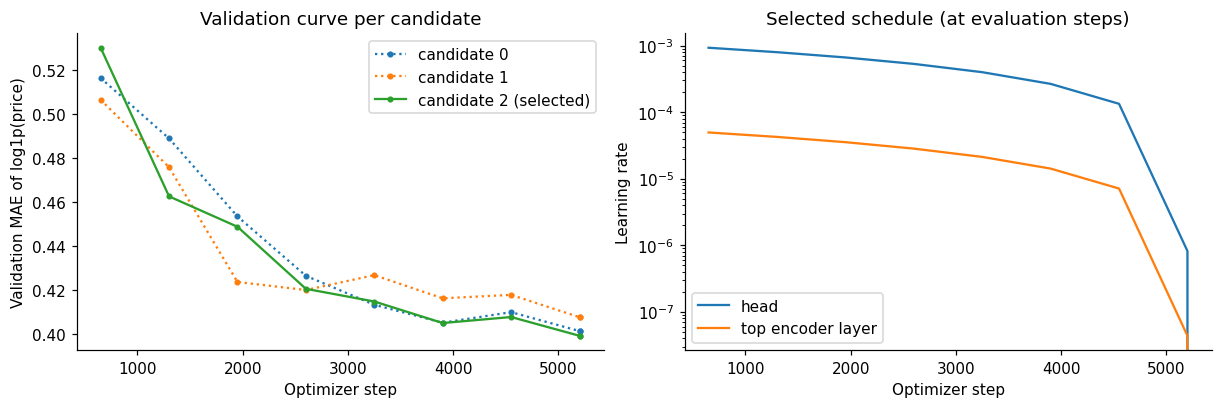

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
for index, history in enumerate(histories):
    style = "-" if index == selected_index else ":"
    ax[0].plot(history.index, history.validation_log_mae, style, marker="o", markersize=3,
               label=f"candidate {index}" + (" (selected)" if index == selected_index else ""))
ax[0].set(xlabel="Optimizer step", ylabel="Validation MAE of log1p(price)",
          title="Validation curve per candidate")
ax[0].legend()
history = histories[selected_index]
ax[1].plot(history.index, history.head_lr, label="head")
ax[1].plot(history.index, history.top_encoder_lr, label="top encoder layer")
ax[1].set(xlabel="Optimizer step", ylabel="Learning rate", yscale="log",
          title="Selected schedule (at evaluation steps)")
ax[1].legend()
plt.show()


## 9. Evaluation

Log-scale predictions are inverse-transformed with `expm1` and bounded between zero and the maximum
training price. MAE and RMSE are in VND, R² is unitless and MAPE is a percentage; metrics use the
complete partitions. The scatterplot shows at most 3,000 fixed-seed test listings, and the residual
histogram displays the central 98% range without removing anything from scoring.

,MAE,RMSE,R2,MAPE
Split,,,,
validation,"6,134,690,971","35,493,078,029",0.1668,"14,380.18"
test,"38,406,194,902","2,966,142,440,479",0.0001,44.85


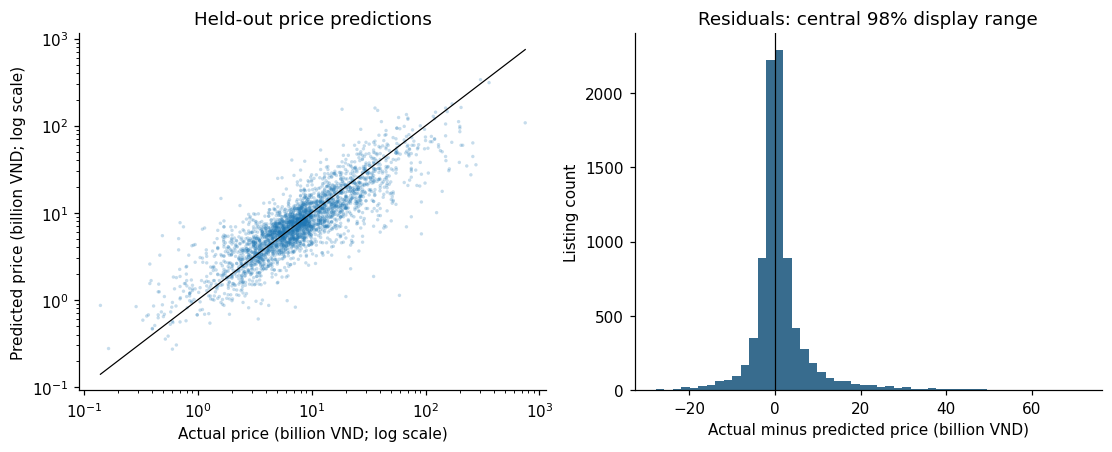

In [9]:
validation_prediction = predict_vnd(model, validation_loader)
test_prediction = predict_vnd(model, test_loader)
extra = {"pretrained_model": MODEL_NAME, "max_length": MAX_LENGTH,
         "best_step": int(model.best_step_), "device": str(DEVICE),
         "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
         "share_truncated_train": float((lengths > MAX_LENGTH).mean())}
result, evaluation_table = record_result(
    "phobert", manifest, parts, validation_prediction, test_prediction,
    selected_parameters, tuning_results, extra=extra)
display(evaluation_table.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                      "R2": "{:.4f}", "MAPE": "{:,.2f}"}))
diagnostics("phobert", test.price, test_prediction)


## 10. Results and Discussion

1. **PhoBERT vs. TF-IDF + Ridge.** Both receive the same redacted text, so the difference measures
   the value of contextual representations and pretraining over a bag of n-grams.
2. **PhoBERT vs. MLP + Embedding.** Text alone against structured attributes alone. The redaction
   deletes every number, including area and room counts, so the text model is expected to lose to
   models that see `area`; how close it gets shows how much the description adds. This motivates
   the fusion model.
3. **Ablation (candidate 1 vs. 0).** The validation difference between naive and full-recipe
   fine-tuning. With one seed per candidate, a small difference should not be over-interpreted.

As in the other notebooks, MAPE is inflated by a few listings with implausibly small recorded prices,
and test RMSE and R² are dominated by one listing at 280 trillion VND, so MAE is the primary metric.
Redaction cannot remove every semantic price cue (e.g. "giá rẻ", "cao cấp"); such cues remain usable
by both text models.

In [10]:
comparison = comparison_table(manifest)
display(comparison.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}",
                                 "R2": "{:.4f}", "MAPE": "{:,.2f}"}))
score = result["metrics"]["test"]
test_mae = comparison.set_index("Model").MAE
naive, tuned = tuning_results.loc[1, "MAE"], tuning_results.loc[0, "MAE"]

def reference(name):
    if name not in test_mae:
        return f"{name}: no comparable result in this bundle (re-pack after running it)"
    return f"{name}: {test_mae[name] / 1e9:.2f} billion VND"

display(Markdown(
    f"The held-out test evaluation gives MAE **{score['MAE']:,.0f} VND** "
    f"({score['MAE'] / 1e9:.2f} billion), RMSE **{score['RMSE']:,.0f} VND**, "
    f"R² **{score['R2']:.4f}**, and MAPE **{score['MAPE']:,.2f}%**.\n\n"
    f"- Same redacted text, bag of n-grams: {reference('TF-IDF + Ridge')}.\n"
    f"- Structured attributes only: {reference('MLP + Embedding')}.\n"
    f"- Fine-tuning ablation (validation MAE): naive candidate 1 {naive / 1e9:.2f} vs. "
    f"full recipe candidate 0 {tuned / 1e9:.2f} billion VND "
    f"({100 * (naive - tuned) / naive:+.1f}% relative to the naive run; positive favours the full recipe)."))


,Model,MAE,RMSE,R2,MAPE
0,Dummy Regressor,"45,548,775,416","2,966,493,482,061",-0.0001,259.20
1,Median Price per sqm,"39,768,818,191","2,968,655,086,029",-0.0016,44.85
2,Ridge Regression,"42,681,233,989","2,971,055,734,676",-0.0032,74.73
3,Random Forest,"37,358,517,200","2,965,843,657,508",0.0003,36.77
4,LightGBM,"36,477,344,778","2,964,995,648,314",0.0009,28.59
5,CatBoost,"37,207,498,640","2,964,647,677,804",0.0011,35.56
6,TF-IDF + Ridge,"39,616,175,623","2,966,358,669,831",-0.0000,54.23
7,MLP + Embedding,"36,584,217,231","2,964,374,461,424",0.0013,29.74
8,PhoBERT + MLP,"38,406,194,902","2,966,142,440,479",0.0001,44.85


The held-out test evaluation gives MAE **38,406,194,902 VND** (38.41 billion), RMSE **2,966,142,440,479 VND**, R² **0.0001**, and MAPE **44.85%**.

- Same redacted text, bag of n-grams: TF-IDF + Ridge: 39.62 billion VND.
- Structured attributes only: MLP + Embedding: 36.58 billion VND.
- Fine-tuning ablation (validation MAE): naive candidate 1 6.19 vs. full recipe candidate 0 6.17 billion VND (+0.4% relative to the naive run; positive favours the full recipe).

## 11. Conclusion

PhoBERT is fine-tuned with layer-wise learning-rate decay, a frozen-encoder head warm-up, separate
warm-up schedules, mixed precision and early stopping, under the same protocol as every other model.
The comparison with TF-IDF isolates the benefit of pretrained contextual representations on identical
information; the ablation measures the contribution of the fine-tuning techniques. The fine-tuned
encoder is the text branch of the fusion model and the subject of the token-level explanation analysis.

Limitations: one seed per candidate and a three-point search; validation reused for early stopping and
selection; 1.5% of listings truncated at 256 tokens; redaction removes physical quantities but not
every semantic price cue; GPU runs are not bit-for-bit reproducible; plus the protocol-wide caveats on
asking prices, entity matching and a single temporal holdout.